# 4.1 Sborové učení, ansámbly - cvičení

Na tomto cvičení si procvičíme následující prvky sborového cvičení:
* Hlasovací klasifikátory
  * Porovnání klasifikátoru pevné a měkké volby
* Bootstrap aggregating
* Důležitost příznaků

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

np.random.seed(23)

/home/lukas/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Hlasovací klasifikátor

In [2]:
# vygenerujne si trenovaci dataset
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=500, noise=0.3, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

In [3]:
print(X.shape)
print(y.shape)

(500, 2)
(500,)


In [4]:
# tridy
np.unique(y)

array([0, 1])

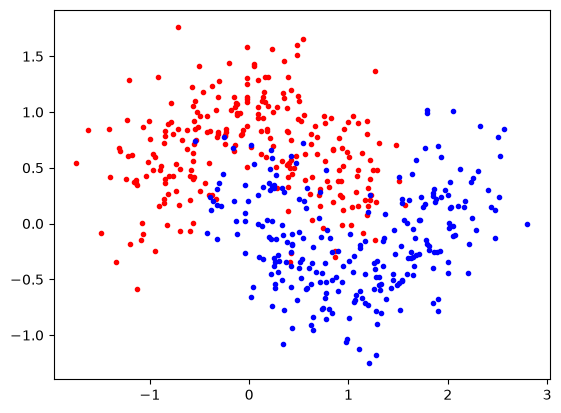

In [5]:
# vizualizace dat 
plt.plot(X[(y==0),0], X[(y==0),1], 'r.')
plt.plot(X[(y==1),0], X[(y==1),1], 'b.')

### Klasifikátor pevné volby

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.ensemble import VotingClassifier

log_reg = LogisticRegression(random_state=42)
rnd_for = RandomForestClassifier(n_estimators=10, random_state=42)
svm_svc = SVC(random_state=42)


voting = VotingClassifier(
    estimators=[('lr', log_reg), ('rf', rnd_for), ('svc', svm_svc)],
    voting='hard'
)

voting.fit(X_train, y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'hard'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...ndom_state=42), RandomForestC...ndom_state=42), SVC(random_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,2


LogisticRegression :  0.864
RandomForestClassifier :  0.872
SVC :  0.896
VotingClassifier :  0.904


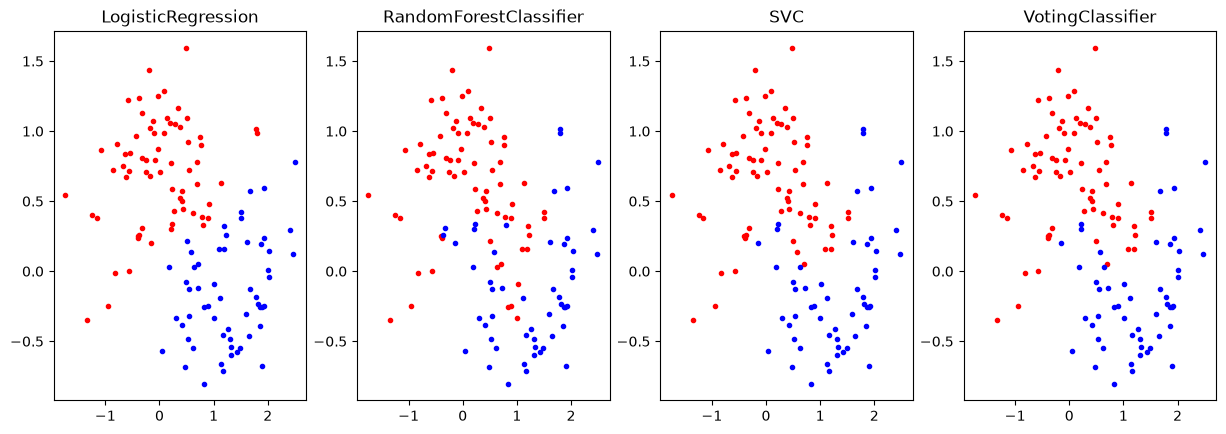

In [7]:
from sklearn.metrics import accuracy_score

models = (log_reg, rnd_for, svm_svc, voting)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

### Klasifikátor měkké volby

In [8]:
log_reg = LogisticRegression(random_state=42)
rnd_for = RandomForestClassifier(n_estimators=10, random_state=42)
svm_svc = SVC(probability=True, random_state=42)

# voting=soft
voting_clf = VotingClassifier(
    estimators=[('lr', log_reg), ('rf', rnd_for), ('svc', svm_svc)],
    voting='soft'
)

voting_clf.fit(X_train, y_train)

/home/lukas/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('lr', ...), ('rf', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'. Note that sub-estimators are always fitted oninteger-encoded labels (see ``le_`` attribute). When ``y`` containsnon-integer class labels (e.g. strings), use ``le_.inverse_transform``to map predictions back to the original label space.",list,"[LogisticRegre...ndom_state=42), RandomForestC...ndom_state=42), SVC(probabili...ndom_state=42)]"
le_ le_: :class:`~sklearn.preprocessing.LabelEncoder`Transformer used to encode the labels during fit and decode duringprediction. Sub-estimators in ``estimators_`` are fitted on theinteger-encoded labels produced by this encoder.,LabelEncoder,LabelEncoder()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying classifier exposes such an attribute when fit... versionadded:: 0.24,int,2


LogisticRegression :  0.864
RandomForestClassifier :  0.872
SVC :  0.896
VotingClassifier :  0.904


/home/lukas/.local/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


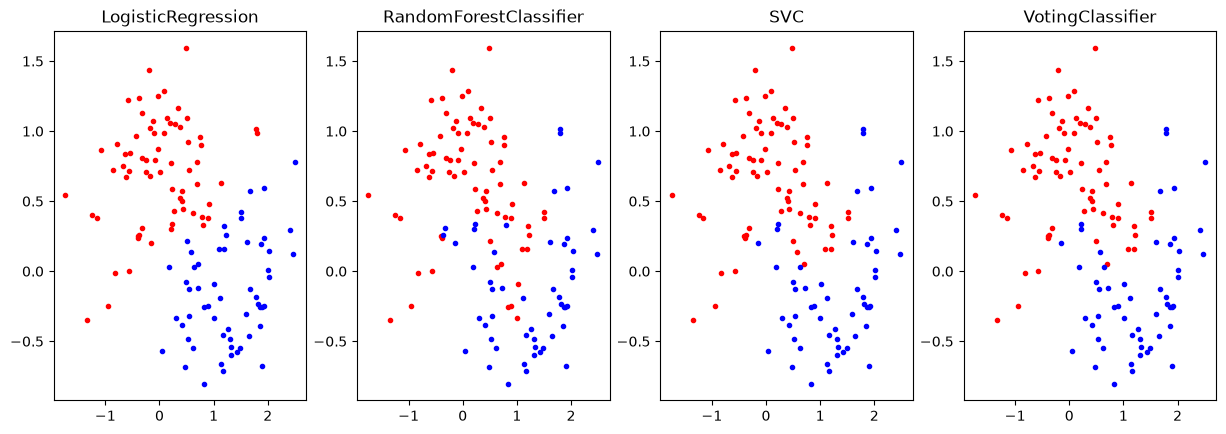

In [9]:
models = (log_reg, rnd_for, svm_svc, voting)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

## Bootstrap aggregating (Bagging)

In [10]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)

bagging = BaggingClassifier(
    dt, n_estimators=500, max_samples=100, bootstrap=True, n_jobs=7,
    random_state=42
)

pasting = BaggingClassifier(
    dt, n_estimators=500, max_samples=100, bootstrap=False, n_jobs=7,
    random_state=42
)

bagging.fit(X_train, y_train)
pasting.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator to fit on random subsets of the dataset.If None, then the base estimator is a:class:`~sklearn.tree.DecisionTreeClassifier`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...ndom_state=42)
,"n_estimators n_estimators: int, default=10The number of base estimators in the ensemble.",500
,"max_samples max_samples: int or float, default=NoneThe number of samples to draw from X to train each base estimator (withreplacement by default, see `bootstrap` for more details).- If None, then draw `X.shape[0]` samples irrespective of `sample_weight`.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` unweighted samples or `max_samples * sample_weight.sum()` weighted samples.",100
,"bootstrap bootstrap: bool, default=TrueWhether samples are drawn with replacement. If False, sampling withoutreplacement is performed. If fitting with `sample_weight`, it isstrongly recommended to choose True, as only drawing with replacementwill ensure the expected frequency semantics of `sample_weight`.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for both :meth:`fit` and:meth:`predict`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random resampling of the original dataset(sample wise and feature wise).If the base estimator accepts a `random_state` attribute, a differentseed is generated for each instance in the ensemble.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator (without replacement by default, see `bootstrap_features` for moredetails).- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.",1.0
,"bootstrap_features bootstrap_features: bool, default=FalseWhether features are drawn with replacement.",False
,"oob_score oob_score: bool, default=FalseWhether to use out-of-bag samples to estimatethe generalization error. Only available if bootstrap=True.",False
,"warm_start warm_start: bool, default=FalseWhen set to True, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fita whole new ensemble. See :term:`the Glossary <warm_start>`... versionadded:: 0.17 *warm_start* constructor parameter.",False
,"verbose verbose: int, default=0Controls the verbosity when fitting and predicting.",0


DecisionTreeClassifier :  0.856
BaggingClassifier :  0.904
BaggingClassifier :  0.92


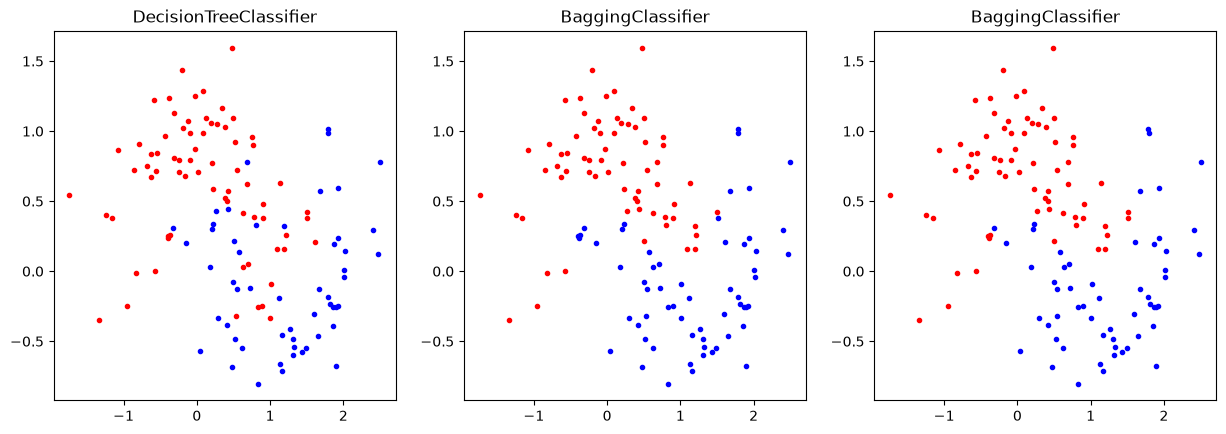

In [11]:
models = (dt, bagging, pasting)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

### Náhodné lesy

In [13]:
from sklearn.ensemble import RandomForestClassifier

rnd_for = RandomForestClassifier(
    n_estimators=500, max_samples=100, n_jobs=7, max_features=1.0,
    random_state=42
)

BaggingClassifier :  0.904
RandomForestClassifier :  0.904


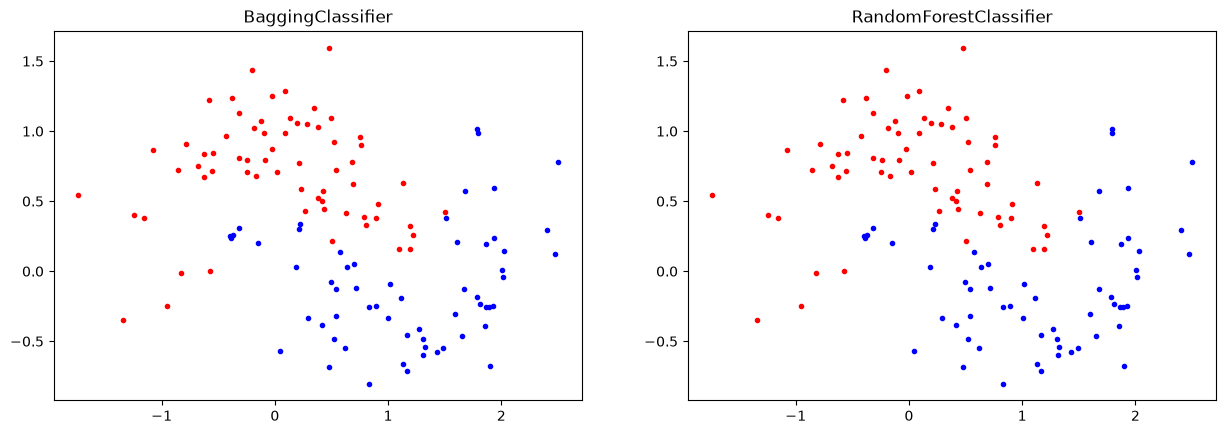

In [14]:
models = (bagging, rnd_for)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))

### Out-of-Bag přesnost

In [15]:
bagging = BaggingClassifier(
    dt, n_estimators=500, max_samples=100, bootstrap=True, n_jobs=-1, 
    oob_score=True, random_state=42
)

bagging.fit(X_train, y_train)

print(bagging.oob_score_) 

0.9253333333333333


## Důležitost příznaků

In [16]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1)

In [17]:
mnist.target

0        5
1        0
2        4
3        1
4        9
        ..
69995    2
69996    3
69997    4
69998    5
69999    6
Name: class, Length: 70000, dtype: category
Categories (10, str): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

In [18]:
mnist.target = mnist.target.astype(np.int64)

In [19]:
mnist.data.head()

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


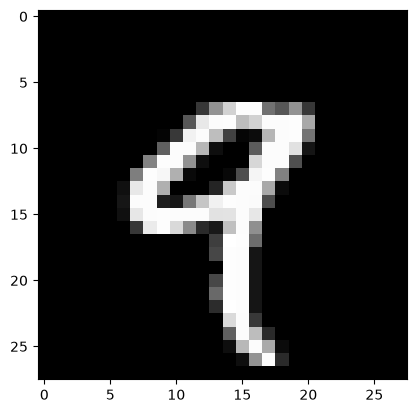

In [24]:
plt.imshow(mnist.data.loc[4].values.reshape(28, 28), cmap=matplotlib.cm.gray, interpolation="nearest")

In [25]:
rnd_for = RandomForestClassifier(n_estimators=10, random_state=42)
rnd_for.fit(mnist["data"], mnist["target"])

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [27]:
rnd_for.feature_importances_.shape

(784,)

In [28]:
np.sum(rnd_for.feature_importances_)

np.float64(1.0)

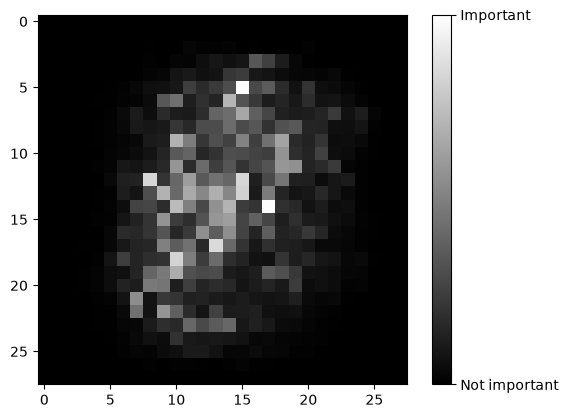

In [29]:
plt.imshow(rnd_for.feature_importances_.reshape(28, 28), cmap=matplotlib.cm.gray, interpolation="nearest")
# plt.axis("off")

cbar = plt.colorbar(ticks=[rnd_for.feature_importances_.min(), rnd_for.feature_importances_.max()])
cbar.ax.set_yticklabels(['Not important', 'Important'])

plt.show()

## AdaBoost

In [22]:
from sklearn.ensemble import AdaBoostClassifier

In [23]:
ada = AdaBoostClassifier(
    DecisionTreeClassifier(max_depth=1), algorithm='SAMME', n_estimators=100, learning_rate=0.5,
    random_state=42
)

RandomForestClassifier :  0.872
AdaBoostClassifier :  0.896


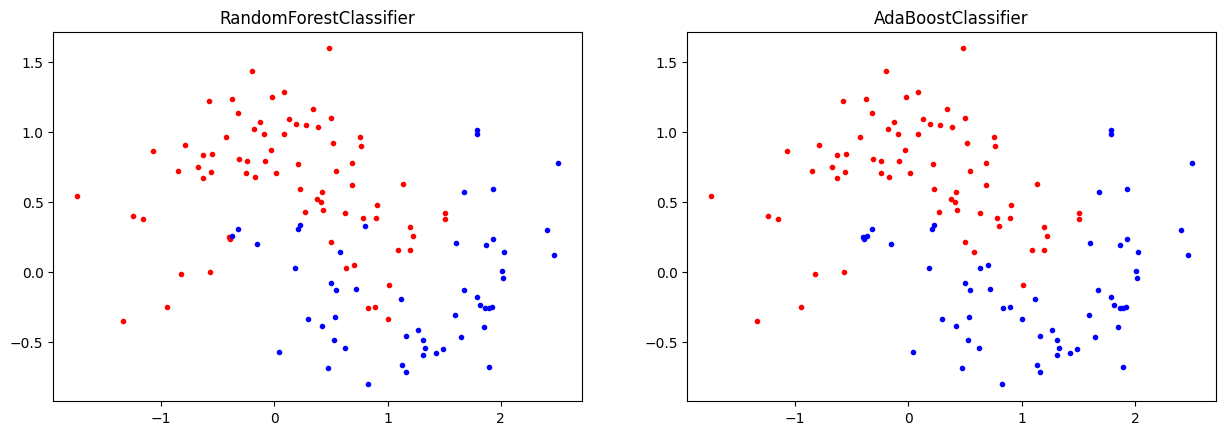

In [24]:
models = (rnd_for, ada)
fig, axes = plt.subplots(1, len(models))
fig.set_figwidth(15)

for i, clf in enumerate(models):
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    axes[i].plot(X_test[(y_pred==0),0], X_test[(y_pred==0),1], 'r.')
    axes[i].plot(X_test[(y_pred==1),0], X_test[(y_pred==1),1], 'b.')
    axes[i].set_title(clf.__class__.__name__)
    print(clf.__class__.__name__,': ', accuracy_score(y_test, y_pred))